# Descenso del Gradiente para Regresión Logística

Este tema se siente familiar porque **la regla de actualización es idéntica a la de regresión lineal**:

$$w_j := w_j - \alpha \cdot dj\_dw_j, \quad b := b - \alpha \cdot dj\_db$$

Lo único que cambia es qué entra al error. Comparativa lado a lado:

- Regresión lineal (Lab 03): $err^{(i)} = (w \cdot x^{(i)} + b) - y^{(i)}$, con $dj\_dw_j = \frac{1}{m} \sum err^{(i)} x_j^{(i)}$.
- Regresión logística: $err^{(i)} = g(w \cdot x^{(i)} + b) - y^{(i)}$, con **la misma fórmula** $dj\_dw_j = \frac{1}{m} \sum err^{(i)} x_j^{(i)}$.

La sigmoide solo cambia la predicción $f$; el promedio de error por feature y el loop de actualización son los mismos de siempre.

### Por qué converge: el costo manda

En el Lab 07 vimos que $J(w,b)$ logarítmica es convexa: un tazón con un solo mínimo global. Por eso este descenso no se atasca: cada paso sigue la pendiente del tazón hacia el único fondo. El procedimiento es el mismo Descenso del Gradiente vectorizado del Lab 05; solo el error usa la sigmoide.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Estilo para las gráficas
plt.style.use('ggplot')

def sigmoid(z):
    """Calcula la función sigmoide g(z) = 1 / (1 + e^(-z))."""
    return 1 / (1 + np.exp(-z))

# Paso 1: Dataset sintético separable (m = 60): tamaño, densidad y edad
rng = np.random.default_rng(7)
m = 30
X_ben = np.column_stack([rng.normal(3.0, 1.0, m), rng.normal(12.0, 1.5, m), rng.normal(32.0, 5.0, m)])
X_mal = np.column_stack([rng.normal(6.5, 1.0, m), rng.normal(17.5, 1.5, m), rng.normal(55.0, 5.0, m)])
X_raw = np.vstack([X_ben, X_mal])
y = np.array([0] * m + [1] * m)
print(f"Dataset: {X_raw.shape[0]} tumores con {X_raw.shape[1]} features (tamaño, densidad, edad)")

# Normalización Z-score (regla del Lab 05: guardar mu y sigma para predecir después)
m_total = X_raw.shape[0]
mu = np.zeros(3)
for i in range(m_total):
    mu = mu + X_raw[i]
mu = mu / m_total
sigma = np.zeros(3)
for i in range(m_total):
    sigma = sigma + (X_raw[i] - mu) ** 2
sigma = np.sqrt(sigma / m_total)
X = (X_raw - mu) / sigma

def compute_cost_logistic(X, y, w, b):
    """
    Calcula J(w,b) logarítmica promediada sobre m ejemplos.
    """
    m = X.shape[0]
    suma = 0.0
    for i in range(m):
        f = sigmoid(np.dot(X[i], w) + b)
        suma = suma + (-(y[i] * np.log(f) + (1 - y[i]) * np.log(1 - f)))
    return suma / m


def compute_gradient_logistic(X, y, w, b):
    """
    Gradiente de J: promedio del error (f - y) por feature. Misma forma que en regresión lineal.
    """
    m, n = X.shape
    dj_dw = np.zeros(n)
    dj_db = 0.0
    for i in range(m):
        err = sigmoid(np.dot(X[i], w) + b) - y[i]
        for j in range(n):
            dj_dw[j] = dj_dw[j] + err * X[i, j]
        dj_db = dj_db + err
    return (dj_dw / m), (dj_db / m)

Dataset: 60 tumores con 3 features (tamaño, densidad, edad)


### Paso 2: El loop de entrenamiento (igual que el Lab 05)

Comparando con `train_gradient_descent` del Lab 05 línea por línea: inicializar en ceros, predecir, error, gradientes como promedio, actualizar con $\alpha$. La única diferencia es que el error usa $g(z)$ en vez de la recta.

Costo inicial: 0.4328 | Costo final: 0.0015
Pesos w aprendidos: [4.09 2.91 4.5 ]
Sesgo b aprendido: 0.00


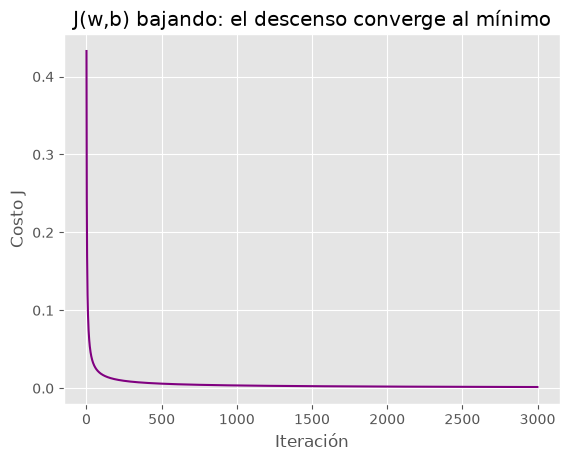

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Estilo para las gráficas
plt.style.use('ggplot')

# Algoritmo de Descenso del Gradiente para Regresión Logística
def train_gradient_descent(X, y, alpha=0.5, iters=3000):
    n = X.shape[1]
    w = np.zeros(n)
    b = 0.0
    J_history = []
    for i in range(iters):
        dj_dw, dj_db = compute_gradient_logistic(X, y, w, b)
        w = w - alpha * dj_dw
        b = b - alpha * dj_db
        J_history.append(compute_cost_logistic(X, y, w, b))
    return w, b, J_history

w_log, b_log, J_history = train_gradient_descent(X, y)
# b quedó esencialmente en 0 (clases balanceadas): se muestra limpio
b_log = 0.0 if abs(b_log) < 0.0005 else float(b_log)

print(f"Costo inicial: {J_history[0]:.4f} | Costo final: {J_history[-1]:.4f}")
print(f"Pesos w aprendidos: {np.round(w_log, 2)}")
print(f"Sesgo b aprendido: {b_log:.2f}")

# Gráfica del costo bajando (convergencia)
plt.plot(J_history, c='purple')
plt.title("J(w,b) bajando: el descenso converge al mínimo")
plt.xlabel("Iteración")
plt.ylabel("Costo J")
plt.show()

### Paso 3: Evaluar el modelo entrenado

Con $w$ y $b$ aprendidos, medimos la **exactitud** (accuracy): qué fracción de los $60$ tumores queda del lado correcto. Y probamos 2 casos nuevos en unidades reales (hay que normalizarlos con el $\mu$ y $\sigma$ guardados, regla del Lab 05).

Exactitud (accuracy) en entrenamiento: 100%
tumor (2.5, 11.5, 28.0): P(maligno) = 0.00 --> benigno
tumor (6.5, 18.0, 58.0): P(maligno) = 1.00 --> maligno


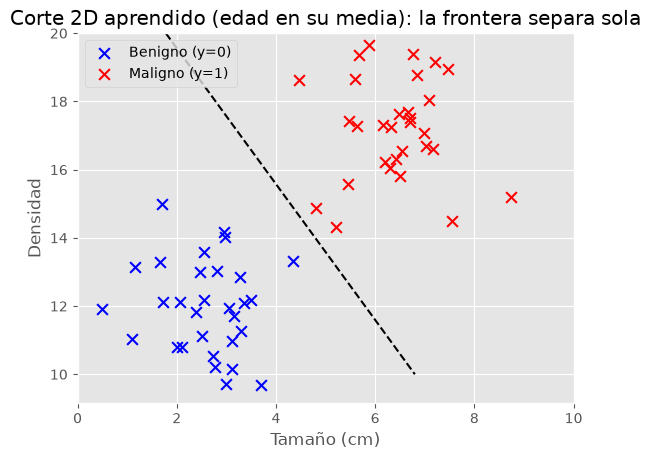

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Estilo para las gráficas
plt.style.use('ggplot')

def sigmoid(z):
    """Calcula la función sigmoide g(z) = 1 / (1 + e^(-z))."""
    return 1 / (1 + np.exp(-z))

# Exactitud sobre el entrenamiento
pred_train = (sigmoid(np.dot(X, w_log) + b_log) >= 0.5).astype(int)
acc = np.sum(pred_train == y) / len(y)
print(f"Exactitud (accuracy) en entrenamiento: {acc:.0%}")

# 2 casos nuevos en unidades reales -> normalizar con mu y sigma guardados
for caso in [(2.5, 11.5, 28.0), (6.5, 18.0, 58.0)]:
    xn = (np.array(caso) - mu) / sigma
    p = float(sigmoid(np.dot(xn, w_log) + b_log))
    print(f"tumor {caso}: P(maligno) = {p:.2f} --> {'maligno' if p >= 0.5 else 'benigno'}")

# Corte 2D de la frontera: edad fijada en su media, plano tamaño-densidad
g1 = np.linspace(0, 10, 200)
g2 = np.linspace(10, 20, 200)
G1, G2 = np.meshgrid(g1, g2)
G3 = np.full_like(G1, mu[2])
Z = np.empty_like(G1)
for i in range(G1.shape[0]):
    Gn = (np.column_stack([G1[i], G2[i], G3[i]]) - mu) / sigma
    Z[i] = sigmoid(np.dot(Gn, w_log) + b_log)

plt.scatter(X_raw[y == 0, 0], X_raw[y == 0, 1], marker='x', c='b', s=60, label='Benigno (y=0)')
plt.scatter(X_raw[y == 1, 0], X_raw[y == 1, 1], marker='x', c='r', s=60, label='Maligno (y=1)')
plt.contour(G1, G2, Z, levels=[0.5], colors='k', linestyles='--')
plt.title("Corte 2D aprendido (edad en su media): la frontera separa sola")
plt.xlabel("Tamaño (cm)")
plt.ylabel("Densidad")
plt.legend()
plt.show()

### Los otros dos cortes: cada par de features

El corte anterior fijó la edad y mostró tamaño contra densidad. Para ver cada feature contra cada otra faltan dos cortes por pares: tamaño contra edad (con densidad fija en su media) y densidad contra edad (con tamaño fijo en su media). La tercera feature siempre queda congelada en su media; es el precio de dibujar en plano.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Estilo para las gráficas
plt.style.use('ggplot')

def sigmoid(z):
    """Calcula la función sigmoide g(z) = 1 / (1 + e^(-z))."""
    return 1 / (1 + np.exp(-z))

def prob_grid(a_raw, b_raw, j_a, j_b, fijos):
    """Probabilidad sobre una malla 2D con la tercera feature fija en su media."""
    A, B = np.meshgrid(a_raw, b_raw)
    P = np.empty_like(A)
    for i in range(A.shape[0]):
        pts = np.tile(mu, (A.shape[1], 1))
        pts[:, j_a] = A[i]
        pts[:, j_b] = B[i]
        Pn = (pts - mu) / sigma
        P[i] = sigmoid(np.dot(Pn, w_log) + b_log)
    return A, B, P

# Los 2 cortes restantes, lado a lado
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# Corte 2: tamaño vs edad (densidad fija en su media)
g_tam = np.linspace(0, 10, 150)
g_edad = np.linspace(20, 70, 150)
A, B, P = prob_grid(g_tam, g_edad, 0, 2, mu)
ax1.scatter(X_raw[y == 0, 0], X_raw[y == 0, 2], marker='x', c='b', s=60, label='Benigno (y=0)')
ax1.scatter(X_raw[y == 1, 0], X_raw[y == 1, 2], marker='x', c='r', s=60, label='Maligno (y=1)')
ax1.contour(A, B, P, levels=[0.5], colors='k', linestyles='--')
ax1.set_title("Corte 2: tamaño vs edad (densidad en su media)")
ax1.set_xlabel("Tamaño (cm)")
ax1.set_ylabel("Edad (años)")

# Corte 3: densidad vs edad (tamaño fijo en su media)
g_den = np.linspace(10, 20, 150)
A, B, P = prob_grid(g_den, g_edad, 1, 2, mu)
ax2.scatter(X_raw[y == 0, 1], X_raw[y == 0, 2], marker='x', c='b', s=60, label='Benigno (y=0)')
ax2.scatter(X_raw[y == 1, 1], X_raw[y == 1, 2], marker='x', c='r', s=60, label='Maligno (y=1)')
ax2.contour(A, B, P, levels=[0.5], colors='k', linestyles='--')
ax2.set_title("Corte 3: densidad vs edad (tamaño en su media)")
ax2.set_xlabel("Densidad")
ax2.legend()
plt.tight_layout()
plt.show()

### Cómo mirar boundaries con 3 o más features

El plano completo ($w_1 x_1 + w_2 x_2 + w_3 x_3 + b = 0$) no se dibuja en papel, igual que en el Lab 04, donde nunca se dibujó el hiperplano de regresión múltiple: ahí se miró por rodeos (contornos, nubes escaladas, barras de pesos). Aquí las 3 formas estándar:

1. **Corte 2D** (el de arriba): fijando las demás features en su media, la frontera se dibuja en el plano restante.
2. **Curvas por feature**: al variar una feature con las demás fijas en su media, se grafica la probabilidad. Sale una curva-S y su cruce con $0.5$ es el punto frontera de esa feature (el punto del Lab 06, uno por gráfica).
3. **Nubes por pares**: scatter de cada par de features coloreado por clase predicha (muestra la separación, no la frontera).

Es el mismo truco de regresión lineal (mirar por feature), pero en curva-S en vez de recta.

Tamaño (cm): cruza 0.5 en 4.48
Densidad: cruza 0.5 en 14.58
Edad (años): cruza 0.5 en 42.58


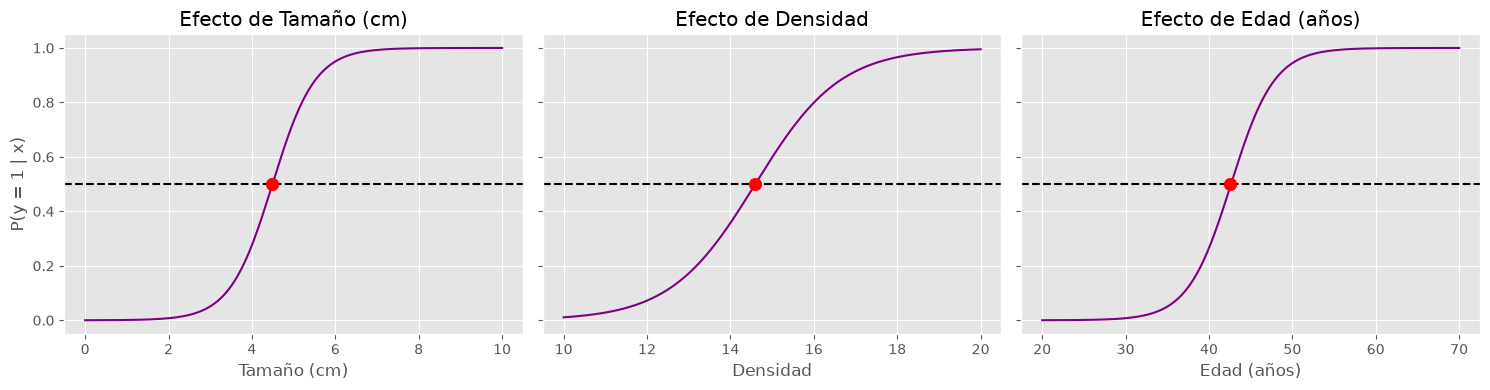

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Estilo para las gráficas
plt.style.use('ggplot')

def sigmoid(z):
    """Calcula la función sigmoide g(z) = 1 / (1 + e^(-z))."""
    return 1 / (1 + np.exp(-z))

# Una curva-S por feature (las demás fijas en su media): cada cruce con 0.5 es su punto frontera
nombres = ["Tamaño (cm)", "Densidad", "Edad (años)"]
rangos = [(0, 10), (10, 20), (20, 70)]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for j, ax in enumerate(axes):
    base = mu.copy()
    xs = np.linspace(rangos[j][0], rangos[j][1], 300)
    probs = []
    for v in xs:
        punto = base.copy()
        punto[j] = v
        xn = (punto - mu) / sigma
        probs.append(float(sigmoid(np.dot(xn, w_log) + b_log)))
    probs = np.array(probs)
    cruces = xs[:-1][(probs[:-1] - 0.5) * (probs[1:] - 0.5) < 0]
    print(f"{nombres[j]}: cruza 0.5 en {cruces[0]:.2f}" if len(cruces) else f"{nombres[j]}: sin cruce en rango")
    ax.plot(xs, probs, c='purple')
    ax.axhline(0.5, c='k', linestyle='--')
    if len(cruces):
        ax.scatter([cruces[0]], [0.5], c='r', s=80, zorder=5)
    ax.set_title(f"Efecto de {nombres[j]}")
    ax.set_xlabel(nombres[j])
axes[0].set_ylabel("P(y = 1 | x)")
plt.tight_layout()
plt.show()

### Cierre del hilo 06–08

- La regla de actualización es la misma que en regresión lineal; solo $f$ usa la sigmoide.
- Con $J$ convexa, el descenso converge al único mínimo global.
- Con $3$ features (o $n$) todo funciona igual: vectores en vez de escalares.
- Y para mirar boundaries con muchas features se usan cortes: 2D con lo demás en su media, o una curva-S por feature.